# Jobsheet 07 - Lab 2: Klasterisasi Data Non-Linear: K-Means vs DBSCAN
**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Institusi:** Jurusan Teknologi Informasi - Politeknik Negeri Malang  
**Topik:** Perbandingan Kemampuan K-Means dan DBSCAN dalam Mengelompokkan Data Berbentuk Non-Linear (Two Moons), serta Evaluasi Menggunakan Silhouette Score dan Davies-Bouldin Index (DBI)


## Langkah 0 - Import Library
Impor modul visualisasi dan algoritma klasterisasi yang dibutuhkan.


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## Langkah 1 - Membuat Dataset Sintetis Non-Linear (Make Moons)
Kita membangkitkan data sintetis berbentuk dua bulan sabit saling mengunci (*two interlocking half moons*) menggunakan fungsi `make_moons` dengan 200 sampel dan parameter `noise=0.05`.


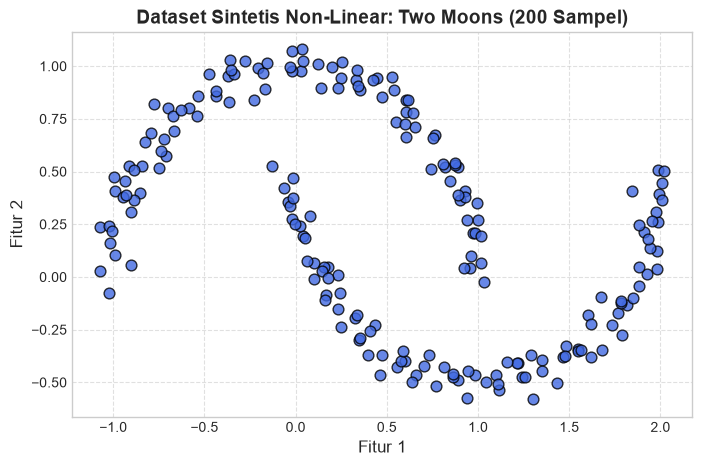

In [2]:
# Generate data sintetis non-linear
X, y = make_moons(200, noise=0.05, random_state=0)

# Visualisasi sebaran data sintetis
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=60, color='royalblue', edgecolors='k', alpha=0.8)
plt.title('Dataset Sintetis Non-Linear: Two Moons (200 Sampel)', fontsize=14, fontweight='bold')
plt.xlabel('Fitur 1', fontsize=12)
plt.ylabel('Fitur 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


Secara visual manusia, kita dapat mengenali dua klaster berbentuk kurva sabit melengkung yang saling mengunci. Bentuk ini tidak cembung (*non-convex*) dan tidak dapat dipisahkan secara linier.


## Langkah 2 - Klasterisasi dengan K-Means
Kita menguji performa K-Means dengan parameter $k=2$ pada data non-linear ini.


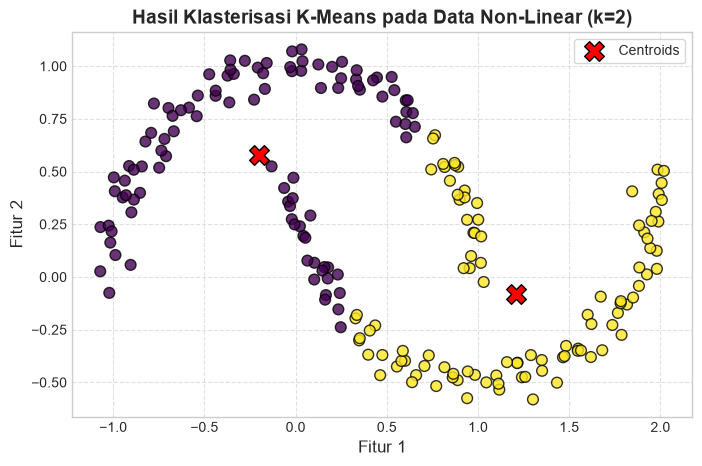

In [3]:
# Pemodelan K-Means (k=2)
kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
cluster = kmeans.fit_predict(X)

# Visualisasi hasil klasterisasi K-Means
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster, s=60, cmap='viridis', edgecolors='k', alpha=0.8)
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', edgecolors='black', label='Centroids')
plt.title('Hasil Klasterisasi K-Means pada Data Non-Linear (k=2)', fontsize=14, fontweight='bold')
plt.xlabel('Fitur 1', fontsize=12)
plt.ylabel('Fitur 2', fontsize=12)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [4]:
# Evaluasi Silhouette Score K-Means
score_km = silhouette_score(X, cluster)
print(f"Silhouette Score K-Means: {score_km}")


Silhouette Score K-Means: 0.49215648268306905


### Analisis K-Means pada Data Non-Linear:
K-Means membagi data menggunakan garis linier imajiner (*hyperplane*) karena ia mengasumsikan klaster berbentuk bola sferis cembung (*convex spherical clusters*) berbasis jarak Euclidean ke titik tengah. Akibatnya, kedua sabit saling terpotong melintang dan menghasilkan pengelompokan yang salah secara struktur pola.


## Langkah 3 - Klasterisasi dengan DBSCAN
DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) mengelompokkan data berdasarkan kerapatan titik tetangga dalam radius $\epsilon$ (*epsilon*). Kita gunakan $\epsilon = 0.3$ dan $	ext{min\_samples} = 2$.


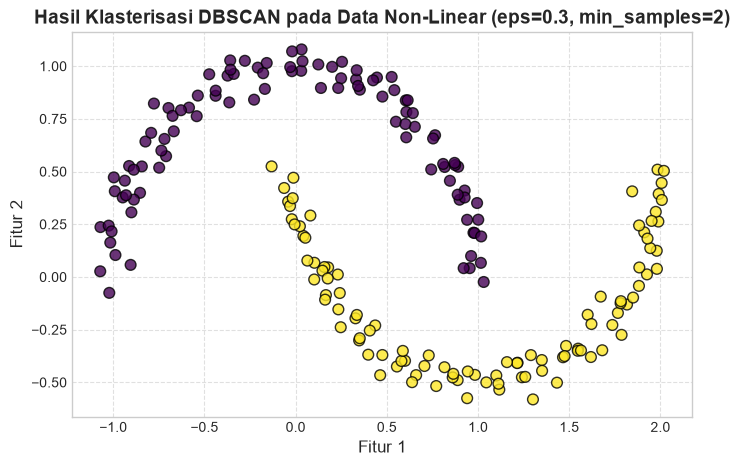

In [5]:
# Pemodelan DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=2)
cluster_db = dbscan.fit_predict(X)

# Visualisasi hasil klasterisasi DBSCAN
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster_db, s=60, cmap='viridis', edgecolors='k', alpha=0.8)
plt.title('Hasil Klasterisasi DBSCAN pada Data Non-Linear (eps=0.3, min_samples=2)', fontsize=14, fontweight='bold')
plt.xlabel('Fitur 1', fontsize=12)
plt.ylabel('Fitur 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [6]:
# Evaluasi Silhouette Score DBSCAN
score_db = silhouette_score(X, cluster_db)
print(f"Silhouette Score DBSCAN: {score_db}")


Silhouette Score DBSCAN: 0.32585318950197517


### Mengapa Silhouette Score DBSCAN Lebih Rendah (0.3259 vs 0.4922)?
Meskipun DBSCAN berhasil memisahkan bentuk bulan sabit dengan sempurna secara visual:
- **Silhouette Coefficient** menghitung rasio jarak rata-rata dalam klaster ($a$) terhadap jarak rata-rata ke klaster terdekat ($b$) menggunakan **jarak Euclidean langsung**.
- Pada bentuk sabit non-linear yang saling melingkar, titik di ujung sabit sebenarnya sangat dekat secara Euclidean dengan sabit di seberangnya, sehingga rumus Silhouette menganggap titik tersebut tidak terpisah dengan baik secara geometri cembung.
- Oleh karena itu, metrik berbasis jarak Euclidean langsung tidak cocok untuk mengevaluasi data dengan geometri arbitrary/non-linear.


## Evaluasi Lanjutan: Davies-Bouldin Index (DBI)
Davies-Bouldin Index mengukur rasio kesamaan antar-klaster (jarak antar-centroid vs dispersi internal klaster). Semakin kecil nilai DBI (mendekati 0), separasi klaster dianggap semakin baik.


In [7]:
# Compute and print Davies-Bouldin Index
db = davies_bouldin_score(X, cluster_db)
print(f"Davies-Bouldin Index: {db}")


Davies-Bouldin Index: 1.1622685374061352


### Kesimpulan Lab 2:
1. **DBSCAN Unggul pada Pola Non-Linear**: DBSCAN mampu menangkap klaster dengan geometri sembarang (*arbitrary shapes*) karena beroperasi berdasarkan ketersambungan densitas (*density-reachability*), bukan bentuk cembung.
2. **Keterbatasan Metrik Validasi**: Metrik internal berbasis jarak pusat (seperti Silhouette Coefficient dan DBI) memiliki bias inheren terhadap klaster berbentuk cembung/sferis. Pada klaster non-linear, inspeksi visual dan analisis persentase noise menjadi kriteria verifikasi yang sangat krusial.
